In [1]:
!pip install kagglehub

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("aceeedev/hackathons")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\admin\.cache\kagglehub\datasets\aceeedev\hackathons\versions\3


In [3]:
import os

### **prints the name of the file**

In [4]:
files=os.listdir(path)
print(files)

['hackathons_dataset.csv']


### pandas

In [5]:
import pandas as pd

In [6]:
df=pd.read_csv(os.path.join(path,"hackathons_dataset.csv"))
print(df.shape)
df.head()

(10179, 11)


,name,organization_name,location,themes,submission_start_date,submission_end_date,prize_currency,prize_amount,registrations,invite_only,url
0,Google Chrome Built-in AI Challenge,Google,Online,"Beginner Friendly, Machine Learning/AI, Web","Oct 01, 2024","Dec 04, 2024",$,65000,8651,False,https://googlechromeai.devpost.com/
1,Codegeist 2024,Atlassian,Online,"DevOps, Machine Learning/AI, Productivity","Oct 15, 2024","Dec 10, 2024",$,170000,3795,False,https://codegeist.devpost.com/
2,Google Photorealistic 3D Maps Challenge,Google,Online,"Beginner Friendly, Low/No Code, Web","Oct 01, 2024","Nov 20, 2024",$,26000,1769,False,https://google3dmaps.devpost.com/
3,Reddit Games and Puzzles Hackathon,reddit,Online,"Beginner Friendly, Gaming, Web","Nov 20, 2024","Dec 18, 2024",$,101000,2005,False,https://redditgamesandpuzzles.devpost.com/
4,Red Hat and Intel AI Hackathon,Red Hat,Online,"Enterprise, Machine Learning/AI, Open Ended","Oct 21, 2024","Nov 15, 2024",$,15000,1063,False,https://redhat-intel.devpost.com/


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10179 entries, 0 to 10178
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   name                   10178 non-null  object
 1   organization_name      5093 non-null   object
 2   location               10009 non-null  object
 3   themes                 5869 non-null   object
 4   submission_start_date  10179 non-null  object
 5   submission_end_date    10179 non-null  object
 6   prize_currency         10179 non-null  object
 7   prize_amount           10179 non-null  int64 
 8   registrations          10179 non-null  int64 
 9   invite_only            10179 non-null  bool  
 10  url                    10179 non-null  object
dtypes: bool(1), int64(2), object(8)
memory usage: 805.3+ KB


In [8]:
print(df.isnull().sum())

name                        1
organization_name        5086
location                  170
themes                   4310
submission_start_date       0
submission_end_date         0
prize_currency              0
prize_amount                0
registrations               0
invite_only                 0
url                         0
dtype: int64


In [9]:
print("Duplicates :",df.duplicated().sum())

Duplicates : 0


In [10]:
df["submission_start_date"] = pd.to_datetime(df["submission_start_date"], format="%b %d, %Y", errors="coerce")

In [11]:
df["submission_end_date"] = pd.to_datetime(df["submission_end_date"], format="%b %d, %Y", errors="coerce")


In [12]:
print(df[["submission_start_date", "submission_end_date"]].isnull().sum())
print(df["submission_start_date"].min(), df["submission_start_date"].max())
print(df.dtypes[["submission_start_date", "submission_end_date"]])

submission_start_date    0
submission_end_date      0
dtype: int64
2009-10-06 00:00:00 2024-12-23 00:00:00
submission_start_date    datetime64[ns]
submission_end_date      datetime64[ns]
dtype: object


In [13]:
# 1) Inspect the row with the missing name
print(df[df["name"].isnull()])

      name    organization_name                                location  \
10005  NaN  Univ. of Pittsburgh  University of Pittsburgh - Alumni Hall   

      themes submission_start_date submission_end_date prize_currency  \
10005  AR/VR            2022-01-22          2022-01-24              $   

       prize_amount  registrations  invite_only  \
10005             0              5         True   

                                           url  
10005  https://she-innovates-2022.devpost.com/  


In [14]:
# 2) Fill missing locations
df["location"] = df["location"].fillna("Unknown")

In [15]:
# 3) Confirm
print(df[["name", "location"]].isnull().sum())

name        1
location    0
dtype: int64


In [16]:
df.loc[10005, "name"] = "She Innovates 2022"

In [17]:
print(df.loc[10005, ["name", "url"]])
print(df["name"].isnull().sum())

name                         She Innovates 2022
url     https://she-innovates-2022.devpost.com/
Name: 10005, dtype: object
0


In [18]:
# 1) Fill missing themes with a label so we keep those rows
df["themes"] = df["themes"].fillna("Unknown")
# 2) Turn the string into a list of themes
df["themes_list"] = df["themes"].str.split(",").apply(lambda lst: [t.strip() for t in lst])

In [19]:
print(df[["themes","themes_list"]].head())
print(df["themes_list"].apply(len).describe())

                                        themes  \
0  Beginner Friendly, Machine Learning/AI, Web   
1    DevOps, Machine Learning/AI, Productivity   
2          Beginner Friendly, Low/No Code, Web   
3               Beginner Friendly, Gaming, Web   
4  Enterprise, Machine Learning/AI, Open Ended   

                                     themes_list  
0  [Beginner Friendly, Machine Learning/AI, Web]  
1    [DevOps, Machine Learning/AI, Productivity]  
2          [Beginner Friendly, Low/No Code, Web]  
3               [Beginner Friendly, Gaming, Web]  
4  [Enterprise, Machine Learning/AI, Open Ended]  
count    10179.000000
mean         1.832989
std          0.930060
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max          3.000000
Name: themes_list, dtype: float64


In [20]:
# 1) Add year columns to the main DataFrame
df["start_year"]=df["submission_start_date"].dt.year

themes_df=df.explode("themes_list").rename(columns={"themes_list":"theme"})

In [21]:
#check it
print(df.shape,themes_df.shape)
print(themes_df[["name","start_year","theme"]].head(8))
print(themes_df["theme"].value_counts().head(10))

(10179, 13) (18658, 13)
                                      name  start_year                theme
0      Google Chrome Built-in AI Challenge        2024    Beginner Friendly
0      Google Chrome Built-in AI Challenge        2024  Machine Learning/AI
0      Google Chrome Built-in AI Challenge        2024                  Web
1                           Codegeist 2024        2024               DevOps
1                           Codegeist 2024        2024  Machine Learning/AI
1                           Codegeist 2024        2024         Productivity
2  Google Photorealistic 3D Maps Challenge        2024    Beginner Friendly
2  Google Photorealistic 3D Maps Challenge        2024          Low/No Code
theme
Unknown                4310
Beginner Friendly      2786
Social Good            2122
Open Ended             1469
Machine Learning/AI    1280
Education               960
Web                     591
Blockchain              579
Design                  475
Health                  447
Name: 

In [22]:
print(df[["prize_amount", "registrations"]].describe())
print(df["prize_currency"].value_counts())
print("Zero prize:", (df["prize_amount"] == 0).sum())
print("Zero registrations:", (df["registrations"] == 0).sum())

       prize_amount  registrations
count  1.017900e+04   10179.000000
mean   2.602567e+04     159.492288
std    2.007264e+05     465.702557
min    0.000000e+00      -5.000000
25%    5.000000e+01      26.000000
50%    2.040000e+03      66.000000
75%    1.000000e+04     153.000000
max    1.268712e+07   18614.000000
prize_currency
$       8681
$CAD     482
₹        395
€        298
£        262
MEX$      18
PKR        9
USD$       5
SAR        3
¥          2
Mex$       2
R          2
₽          2
zł         2
INR        2
R$         2
₪          1
Rs         1
ZAR        1
GEL        1
₨          1
ლ          1
 SEK       1
C$         1
PLN        1
SR         1
PLN        1
MYR        1
Name: count, dtype: int64
Zero prize: 2409
Zero registrations: 15


In [23]:
# Negative registrations
print("Negative registrations:", (df["registrations"] < 0).sum())
print(df[df["registrations"] < 0][["name", "registrations", "url"]])

# Top 10 prizes with their currency
print(df.nlargest(10, "prize_amount")[["name", "prize_currency", "prize_amount"]])

Negative registrations: 9
                                             name  registrations  \
210                                 Game for Free             -1   
10171  Student Dreamers Venture One Day Hackathon             -1   
10172                                   TEST HANG             -3   
10173                                    testing2             -1   
10174                           Thailand champion             -2   
10175                         Devpost is a global             -1   
10176                           Manager Hackathon             -5   
10177                                        Giap             -3   
10178                             Hackathon name1             -1   

                                                     url  
210                   https://game-for-free.devpost.com/  
10171  https://student-gmu-one-day-hackathon.devpost....  
10172                     https://test-hang.devpost.com/  
10173                      https://testing2.devpost.com/ 

In [24]:
# 1) Drop the 8 obvious test rows (last 8 rows of the file, negative registrations)
test_idx = df[(df["registrations"] < 0) & (df.index >= 10171)].index
df = df.drop(index=test_idx)

# 2) Row 210: set its invalid registrations to missing instead of dropping
df.loc[210, "registrations"] = pd.NA

# 3) Rebuild themes_df so it matches the cleaned df
themes_df = df.explode("themes_list").rename(columns={"themes_list": "theme"})

# 4) Check
print(df.shape, themes_df.shape)
print("Negative registrations left:", (df["registrations"] < 0).sum())
print(df["registrations"].isnull().sum())

(10171, 13) (18649, 13)
Negative registrations left: 0
1


In [25]:
print(df["registrations"].dtype)
df["registrations"] = df["registrations"].astype("float64")
print(df["registrations"].dtype)

float64
float64


In [26]:
df[df["registrations"] == 0][["name", "prize_amount", "url"]]

,name,prize_amount,url
209,jgjghvhhchcg,0,https://jgjghvhhchcg.devpost.com/
9928,HackWise 2020,0,https://hackwise.devpost.com/
9929,India Innovation Series - Delhi NCR,50000,https://iisdelhi.devpost.com/
9930,COMIT Hackathon - Atomic Swaps for your Applic...,0,https://comit-hackathon.devpost.com/
9931,iXP x IC Hackathon,0,https://ixp-x-ic-hackathon-7851.devpost.com/
9932,Sustainability using IoT,0,https://ericsson-iot-hackathon.devpost.com/
10162,The Community Challenge at Connext 2024,0,https://community-challenge2024.devpost.com/
10163,[EVENT CANCELLED] HP SCDS Hackathon - Heritage...,4500,https://hp-scds-heritage-technology.devpost.com/
10164,Bentham Code,0,https://bentham-code-tech-css.devpost.com/
10165,[OLD] VST Hackathon,2000,https://virtusense-hackathon.devpost.com/


In [30]:
print(df.shape)
print("Dropped rows still present:", df.index.isin([209, 10167, 10170, 10168, 10163, 10165]).sum())
print("Zeros left:", (df["registrations"] == 0).sum())
print("Missing registrations:", df["registrations"].isnull().sum())

themes_df = df.explode("themes_list").rename(columns={"themes_list": "theme"})
print(themes_df.shape)

(10165, 13)
Dropped rows still present: 0
Zeros left: 9
Missing registrations: 1
(18639, 13)


In [31]:
df.loc[df["registrations"] == 0, "registrations"] = np.nan

print("Zeros left:", (df["registrations"] == 0).sum())
print("Missing registrations:", df["registrations"].isnull().sum())

themes_df = df.explode("themes_list").rename(columns={"themes_list": "theme"})
print(df.shape, themes_df.shape)

Zeros left: 0
Missing registrations: 10
(10165, 13) (18639, 13)


In [32]:
bad_dates = df[df["submission_end_date"] < df["submission_start_date"]]
print("Reversed dates:", len(bad_dates))
bad_dates[["name", "submission_start_date", "submission_end_date", "url"]]

Reversed dates: 1


,name,submission_start_date,submission_end_date,url
9779,Green Game Jam for Youth,2021-08-01,2021-07-30,https://green-game-jam-for-youth.devpost.com/


In [33]:
df.loc[9779, "submission_end_date"] = pd.NaT

print("Reversed dates left:", (df["submission_end_date"] < df["submission_start_date"]).sum())
print("Missing end dates:", df["submission_end_date"].isnull().sum())

Reversed dates left: 0
Missing end dates: 1


In [34]:
for col in ["name", "location", "organization_name"]:
    df[col] = df[col].str.strip()

themes_df = df.explode("themes_list").rename(columns={"themes_list": "theme"})

print(df.shape, themes_df.shape)
print(df.isnull().sum())

(10165, 13) (18639, 13)
name                        0
organization_name        5085
location                    0
themes                      0
submission_start_date       0
submission_end_date         1
prize_currency              0
prize_amount                0
registrations              10
invite_only                 0
url                         0
themes_list                 0
start_year                  0
dtype: int64


## Saving all the cleaned data

In [35]:
df.drop(columns=["themes_list"]).to_csv("hackathons_clean.csv", index=False)

start_year
2009       1
2010       6
2011      19
2012      31
2013      99
2014     363
2015     633
2016     711
2017     736
2018     800
2019     865
2020     950
2021    1198
2022    1185
2023    1241
2024    1327
dtype: int64
Peak year: 2024 with 1327 hackathons


<Axes: title={'center': 'Hackathons per year'}, xlabel='start_year'>

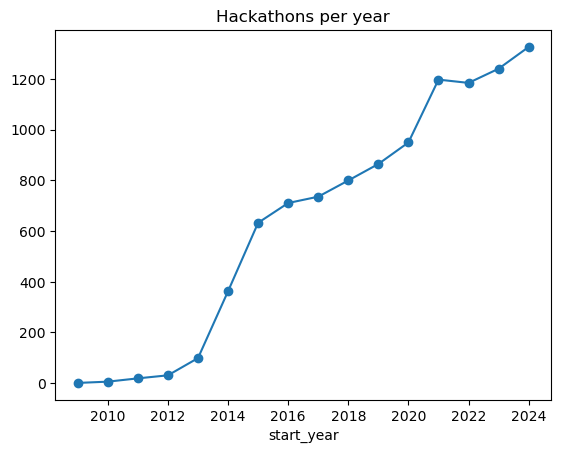

In [36]:
yearly = df.groupby("start_year").size()
print(yearly)
print("Peak year:", yearly.idxmax(), "with", yearly.max(), "hackathons")

yearly.plot(kind="line", marker="o", title="Hackathons per year")

In [37]:
print(yearly)
print("Peak year:", yearly.idxmax(), "with", yearly.max())
print(yearly.sort_values(ascending=False).head(3))

start_year
2009       1
2010       6
2011      19
2012      31
2013      99
2014     363
2015     633
2016     711
2017     736
2018     800
2019     865
2020     950
2021    1198
2022    1185
2023    1241
2024    1327
dtype: int64
Peak year: 2024 with 1327
start_year
2024    1327
2023    1241
2021    1198
dtype: int64


start_year
2009    1.00
2010    1.00
2011    1.00
2012    1.00
2013    1.00
2014    0.95
2015    0.96
2016    0.96
2017    0.96
2018    0.89
2019    0.71
2020    0.41
2021    0.09
2022    0.00
2023    0.00
2024    0.00
Name: themes, dtype: float64
theme       Beginner Friendly  Education  Machine Learning/AI  Open Ended  \
start_year                                                                  
2014                        0          0                    2           0   
2015                        0          0                    0           0   
2016                        0          0                    1           0   
2017                        0          0                    9           0   
2018                        2          0                   10           2   
2019                        3          0                   92           1   
2020                        7          2                  148           3   
2021                      466        240                  1

<Axes: title={'center': 'Top 5 themes per year'}, xlabel='start_year'>

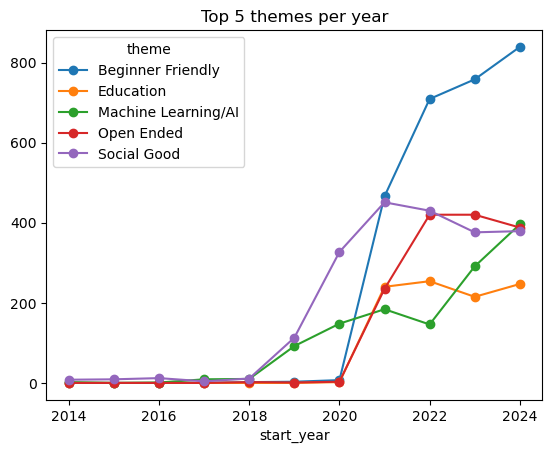

In [38]:
# 1) Share of hackathons with no theme, per year
print(df["themes"].eq("Unknown").groupby(df["start_year"]).mean().round(2))

# 2) Top 5 themes (excluding Unknown) per year
known = themes_df[themes_df["theme"] != "Unknown"]
top5 = known["theme"].value_counts().head(5).index

trend = (known[known["theme"].isin(top5)]
         .groupby(["start_year", "theme"]).size()
         .unstack(fill_value=0))

print(trend.loc[2014:])
trend.loc[2014:].plot(marker="o", title="Top 5 themes per year")

            count       sum   mean  median
start_year                                
2014          363   35671.0   98.3    43.0
2015          633   53030.0   83.8    38.0
2016          711   63238.0   88.9    44.0
2017          736   72519.0   98.5    46.0
2018          800   79279.0   99.1    43.5
2019          861   95719.0  111.2    53.0
2020          949  240588.0  253.5   104.0
2021         1197  229539.0  191.8    91.0
2022         1183  212416.0  179.6    78.0
2023         1241  215011.0  173.3    81.0
2024         1325  297420.0  224.5    75.0
                                                  name  start_year  \
211                      COVID-19 Global Hackathon 1.0        2020   
212                                Google AI Hackathon        2024   
214                                        #WirVsVirus        2020   
213  2019 Developer Circles from Facebook Community...        2019   
215         Microsoft Developers AI Learning Hackathon        2024   
216      The European

array([<Axes: xlabel='start_year'>, <Axes: xlabel='start_year'>],
      dtype=object)

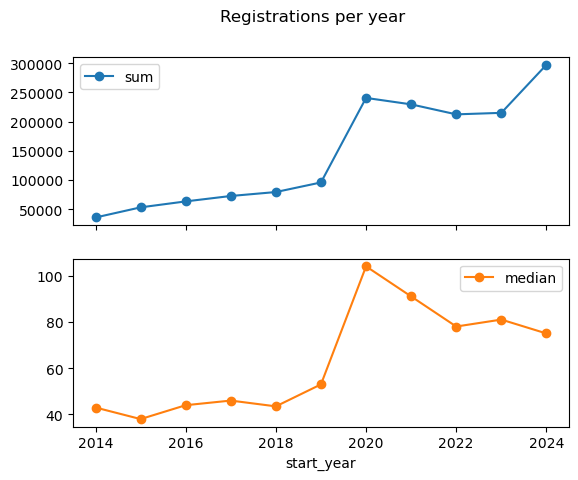

In [39]:
# 1) Registrations per year
part = df.groupby("start_year")["registrations"].agg(["count", "sum", "mean", "median"]).round(1)
print(part.loc[2014:])

# 2) Top 10 hackathons by registrations
print(df.nlargest(10, "registrations")[["name", "start_year", "registrations"]])

# 3) Plot total vs median
part.loc[2014:, ["sum", "median"]].plot(subplots=True, marker="o", title="Registrations per year")

In [1]:
import os
print(os.getcwd())

C:\Users\admin
